## DS 6021: Intro to Predictive Modeling
## Lab 5: Feature Selection, Cross-Validation, and Model Complexity
### Fiona St. Clair
***

AI Disclosure: I used Claude Code to help write and run the code for this lab, using my in-class notebooks as the model for the techniques. I did not use generative AI for any of the written explanations or reflection answers. 
***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, SplineTransformer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import root_mean_squared_error

auto = pd.read_csv("../../../data/Auto.csv", na_values="?").dropna().reset_index(drop=True)
bike = pd.read_csv("../../../data/bike-sharing-daily.csv")
print("cars:", len(auto))
auto.head()

cars: 392


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino


## Part 1: Feature Selection
### Question 1: Data pre-processing + exploration
**a.** Cylinders as a categorical variable

cylinders
3      4
4    199
5      3
6     83
8    103
Name: count, dtype: int64

           count  mean  std   min   25%   50%   75%   max
cylinders                                                
3            4.0  20.6  2.6  18.0  18.8  20.2  22.0  23.7
4          199.0  29.3  5.7  18.0  25.0  28.4  33.0  46.6
5            3.0  27.4  8.2  20.3  22.8  25.4  30.9  36.4
6           83.0  20.0  3.8  15.0  18.0  19.0  21.0  38.0
8          103.0  15.0  2.8   9.0  13.0  14.0  16.0  26.6


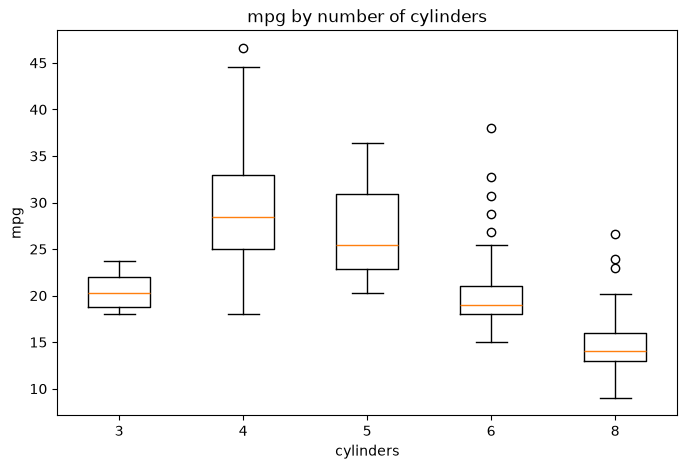

In [2]:
print(auto["cylinders"].value_counts().sort_index())
print()
print(auto.groupby("cylinders")["mpg"].describe().round(1))

cyl_levels = sorted(auto["cylinders"].unique())
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([auto.loc[auto.cylinders == c, "mpg"] for c in cyl_levels], tick_labels=cyl_levels)
ax.set(xlabel="cylinders", ylabel="mpg", title="mpg by number of cylinders")
plt.show()

**b.** Create `cyl_rollup`

In [3]:
auto["cyl_rollup"] = np.select([auto["cylinders"] < 6, auto["cylinders"] == 6, auto["cylinders"] == 8],
                               ["<6", "6", "8"], default="other")
print(pd.crosstab(auto["cylinders"], auto["cyl_rollup"]))

cyl_rollup   6    8   <6
cylinders               
3            0    0    4
4            0    0  199
5            0    0    3
6           83    0    0
8            0  103    0


**c.** Same plot with `cyl_rollup`

            count  mean  std   min   25%   50%   75%   max
cyl_rollup                                                
<6          206.0  29.1  5.8  18.0  25.0  28.0  32.9  46.6
6            83.0  20.0  3.8  15.0  18.0  19.0  21.0  38.0
8           103.0  15.0  2.8   9.0  13.0  14.0  16.0  26.6


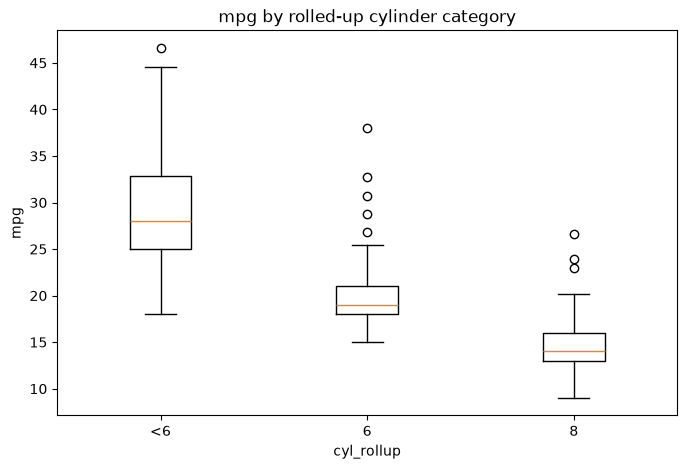

In [4]:
roll_levels = ["<6", "6", "8"]
print(auto.groupby("cyl_rollup")["mpg"].describe().loc[roll_levels].round(1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([auto.loc[auto.cyl_rollup == c, "mpg"] for c in roll_levels], tick_labels=roll_levels)
ax.set(xlabel="cyl_rollup", ylabel="mpg", title="mpg by rolled-up cylinder category")
plt.show()

What do you observe?

***In general, the mpg has an inverse relation to the rolled-up cylinder count. The box plot shows a dropping mean (28 -> 19 -> 24) with little/no overlap between the cylinders (only the whiskers and outliers overlap). The less than 6 cylinder group has the most extreme outlier of around 47 mpg. The 6 cylinder category has the most outliers, 5 in total outside of the box plot. Comparing this to the original graph in part a, we can see that changing 3-5 into <6 did not change the group much (mean 29.3 changed to 29.1 and SD 5.7 to 5.8), which tells us this was a good choice.***

**d.** Why should we exclude `name`?

***We exclude name because there is a different name for nearly every car, so there is no pattern here for the model to learn. Name is only seen as a label in this context; it doesn't actually tell us anything about the car, nor does it help with predicting mpg for newly introduced cars.***

### Question 2: Forward and backward selection

In [5]:
num_cols = ["displacement", "horsepower", "weight", "acceleration", "year"]
Xn = auto[num_cols]
y = auto["mpg"]

# One KFold object, reused for both forward and backward selection
cv = KFold(n_splits=5, shuffle=True, random_state=42)

def make_selector(direction, k):
    return make_pipeline(
        StandardScaler(),
        SequentialFeatureSelector(LinearRegression(), n_features_to_select=k,
                                  direction=direction, cv=cv,
                                  scoring="neg_root_mean_squared_error"))

**a.** Forward selection, k = 1 to 4

In [6]:
for k in range(1, 5):
    sel = make_selector("forward", k).fit(Xn, y)
    print(f"Forward, k={k}:", list(Xn.columns[sel[-1].get_support()]))

Forward, k=1: ['weight']
Forward, k=2: ['weight', 'year']
Forward, k=3: ['displacement', 'weight', 'year']
Forward, k=4: ['displacement', 'horsepower', 'weight', 'year']


**b.** Backward selection with 3 features

In [7]:
back3 = make_selector("backward", 3).fit(Xn, y)
fwd3 = make_selector("forward", 3).fit(Xn, y)
print("Forward, k=3: ", list(Xn.columns[fwd3[-1].get_support()]))
print("Backward, k=3:", list(Xn.columns[back3[-1].get_support()]))

Forward, k=3:  ['displacement', 'weight', 'year']
Backward, k=3: ['displacement', 'weight', 'year']


Do forward and backward selection choose the same three features? If so, does that guarantee the best model? If not, why not?

***Yes, they both choose displacement, weight, and year. Technically, this does not guarantee this is the best model, but the models lining up is good evidence that it may be. This is because both selection types are "greedy" and do not check every single combination possible.***

**c.** Correlations and VIFs for displacement, horsepower, and weight

In [8]:
big3 = ["displacement", "horsepower", "weight"]
print(auto[big3].corr().round(3))

Xv = sm.add_constant(auto[big3])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=big3)
print()
print("VIF:")
print(vif.round(2))

              displacement  horsepower  weight
displacement         1.000       0.897   0.933
horsepower           0.897       1.000   0.865
weight               0.933       0.865   1.000

VIF:
displacement    10.31
horsepower       5.29
weight           7.96
dtype: float64


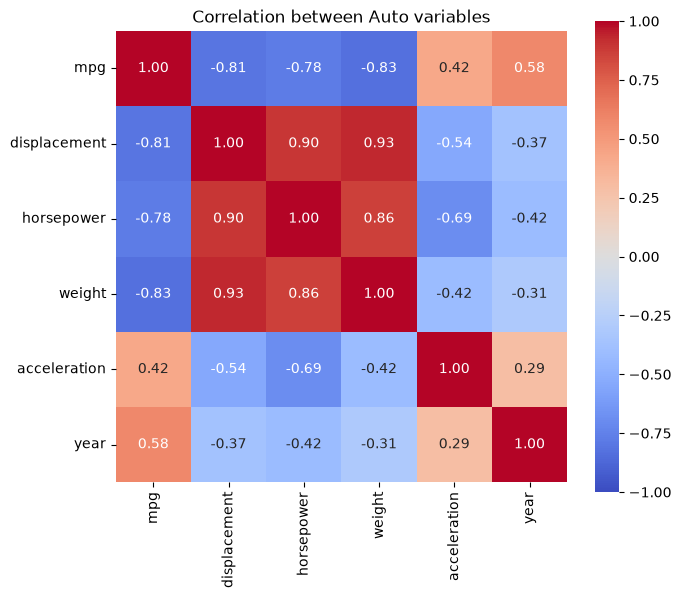

In [9]:
import seaborn as sns

cols = ["mpg", "displacement", "horsepower", "weight", "acceleration", "year"]
corr = auto[cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation between Auto variables")
plt.tight_layout()
plt.show()

For variables with high VIF, how can this affect the features chosen by backward selection? What about forward selection?

***All three variables (displacement at 10.31, horsepower at 5.29, weight at 7.96) have high VIF, meaning these variables are repeating the others. It affects backward selection because it starts with all possible features. When it tests which to drop, they all look like they overlap, so it essentially makes the question of 'which one to drop' a toss-up for all three. For forward selection, it would pick weight (strongest), but when adding the other two variables, it adds much less because weight already said what the other variables say. This doesn't mean the variable should be completely tossed out, however, only that it essentially copies another variable. These variables are all also highly correlated as seen on the heat map (all between .86 and .93), which is evidence as to why the VIFs are so high.***

***
## Part 2: Cross-Validation Approaches

In [10]:
num = ["displacement", "weight", "year"]
cat = ["cyl_rollup", "origin"]

auto["origin"] = auto["origin"].astype(str)   # origin is a category (1 = US, 2 = Europe, 3 = Japan), not a number

XA = auto[num]
XB = auto[num + cat]

modelA = make_pipeline(make_column_transformer((StandardScaler(), num)), LinearRegression())
modelB = make_pipeline(make_column_transformer((StandardScaler(), num),
                                               (OneHotEncoder(drop="first"), cat)),
                       LinearRegression())
models = {"Model A": (modelA, XA), "Model B": (modelB, XB)}

### Question 1: Single 80/20 train/test split

In [11]:
rows = []
for name, (m, X) in models.items():
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    m.fit(X_train, y_train)
    rows.append({"model": name,
                 "train RMSE": root_mean_squared_error(y_train, m.predict(X_train)),
                 "test RMSE": root_mean_squared_error(y_test, m.predict(X_test))})
split_table = pd.DataFrame(rows).set_index("model")
split_table.round(3)

,train RMSE,test RMSE
model,,
Model A,3.460,3.261
Model B,3.226,3.089


**b.** Which model is better and why?

***Model B is better because it has a lower test RMSE by .17 mpg. We compare test RMSE because this is measuring performance on cars the model has not seen before. This isn't a huge amount, only about a sixth of a mile per gallon less than the first model. Compared to the test error ranging from 3.089 to 3.261, it's about a 5% improvement. There are no obvious signs of overfitting, as the test is only slightly lower than the train. It is a bit odd that the test performed better in both models compared to their train. It would be best to repeat this test with different random splits to see how this replicates.***

### Question 2: k-fold cross-validation

In [12]:
def cv_rmse(model, X, y, cv):
    # Score with MSE and take the square root of the mean, as in class
    mse = -cross_val_score(model, X, y, cv=cv, scoring="neg_mean_squared_error")
    return np.sqrt(mse.mean())

rows = []
for name, (m, X) in models.items():
    rows.append({"model": name,
                 "train/test": split_table.loc[name, "test RMSE"],
                 "5-fold": cv_rmse(m, X, y, KFold(5, shuffle=True, random_state=42)),
                 "10-fold": cv_rmse(m, X, y, KFold(10, shuffle=True, random_state=42))})
oos_table = pd.DataFrame(rows).set_index("model")
oos_table.round(3)

,train/test,5-fold,10-fold
model,,,
Model A,3.261,3.445,3.441
Model B,3.089,3.257,3.262


**b.** What patterns do you see across the three out-of-sample RMSE estimates?

***Both models show the same pattern. The single train/test split gives the lowest RMSE (A: 3.261, B: 3.089), and the 5-fold and 10-fold estimates are higher and almost identical to each other (A: 3.445 and 3.441, B: 3.257 and 3.262). The single split looks about 0.17 mpg better than cross-validation for both models, which fits with it being a bit lucky, since it only tests on 78 cars. This also explains why the test error was lower than the train error earlier. 5-fold and 10-fold only differ by about .005, so going from 5 to 10 folds doesn't change much here. The gap between the models stays about the same.***

**c.** Which model would you now say is better and why?

***Model B is still better. It has the lower out of sample RMSE in all three methods. I trust the cross validation numbers more than the single split now because every car gets used as test data once instead of relying on one random 20%. B is better by about 0.18 mpg or about 5%, which is not huge but it is consistent.***

### Question 3: 100 random seeds

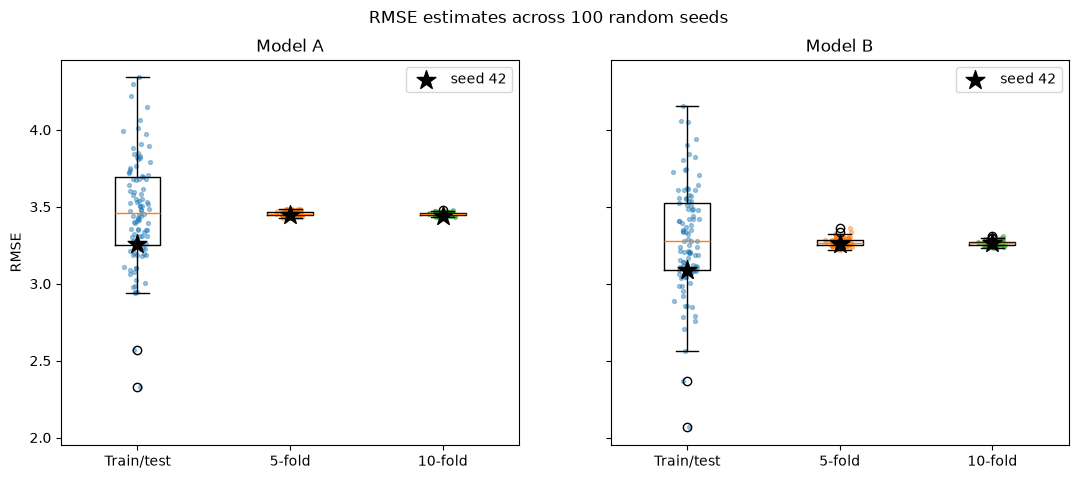

mean    std    min    max
model   method                                
Model A 10-fold     3.454  0.009  3.431  3.482
        5-fold      3.456  0.014  3.427  3.485
        Train/test  3.472  0.344  2.331  4.340
Model B 10-fold     3.264  0.014  3.235  3.307
        5-fold      3.269  0.024  3.222  3.364
        Train/test  3.292  0.349  2.066  4.157

In [13]:
rows = []
for name, (m, X) in models.items():
    for seed in range(100):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
        m.fit(X_train, y_train)
        rows += [
            {"model": name, "method": "Train/test", "seed": seed,
             "rmse": root_mean_squared_error(y_test, m.predict(X_test))},
            {"model": name, "method": "5-fold", "seed": seed,
             "rmse": cv_rmse(m, X, y, KFold(5, shuffle=True, random_state=seed))},
            {"model": name, "method": "10-fold", "seed": seed,
             "rmse": cv_rmse(m, X, y, KFold(10, shuffle=True, random_state=seed))},
        ]
by_seed = pd.DataFrame(rows)

# Same plot as the in-class notebook, drawn once per model on a shared y-axis
# (no "No split" or LOOCV lines, since we weren't asked for those)
order = ["Train/test", "5-fold", "10-fold"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, name in zip(axes, models):
    d = by_seed[by_seed.model == name]
    ax.boxplot([d.loc[d.method == m, "rmse"] for m in order], tick_labels=order)
    for i, m in enumerate(order, start=1):
        vals = d.loc[d.method == m, "rmse"]
        ax.scatter(np.random.default_rng(0).normal(i, 0.04, len(vals)), vals, s=8, alpha=0.4)
        ax.scatter(i, d.loc[(d.method == m) & (d.seed == 42), "rmse"],
                   marker="*", s=200, color="black", zorder=3, label="seed 42" if i == 1 else None)
    ax.set(title=name, ylabel="RMSE" if name == "Model A" else None)
    ax.legend()
fig.suptitle("RMSE estimates across 100 random seeds")
plt.show()

display(by_seed.groupby(["model", "method"])["rmse"].agg(["mean", "std", "min", "max"]).round(3))

**a.** Based on these plots, which model would you choose and why?

***I would choose Model B. In the plots, the Model B boxes sit lower than Model A for all three methods (means of about 3.26 to 3.29 vs 3.45 to 3.47). The train/test split boxes are very wide (SD of about .34, ranging from 2.07 to 4.16 for B and 2.33 to 4.34 for A) and the two models overlap a lot, so depending on the seed a single split could make either one look better. The 5-fold and 10-fold boxes are very narrow (SD of .01 to .02) and the two models do not overlap at all, so we can see that B is better and not just luckier. The k-fold approach is much more stable than a single split.***

**b.** Is adding the categorical variables worth the extra complexity?

***I think yes, but only a little bit. Adding cyl_rollup and origin lowers the RMSE by about 0.19 mpg (3.45 to 3.26, or about 5.5%), and that improvement shows up in every seed with k-fold, so it is real and not a fluke. The cost is 4 more columns (2 for cyl_rollup and 2 for origin) with 392 cars, which isn't a lot of added complexity, and we saw no signs of overfitting (the test error is not worse than A's). On the other hand, 0.19 mpg is small compared to an RMSE of about 3.3, so if we needed a very simple model, Model A would still be fine. I would keep the categorical variables since the improvement is consistent and the cost is low.***

## Part 3: Polynomial and Spline Regression

### Question 1: Fit three models of rentals on temperature

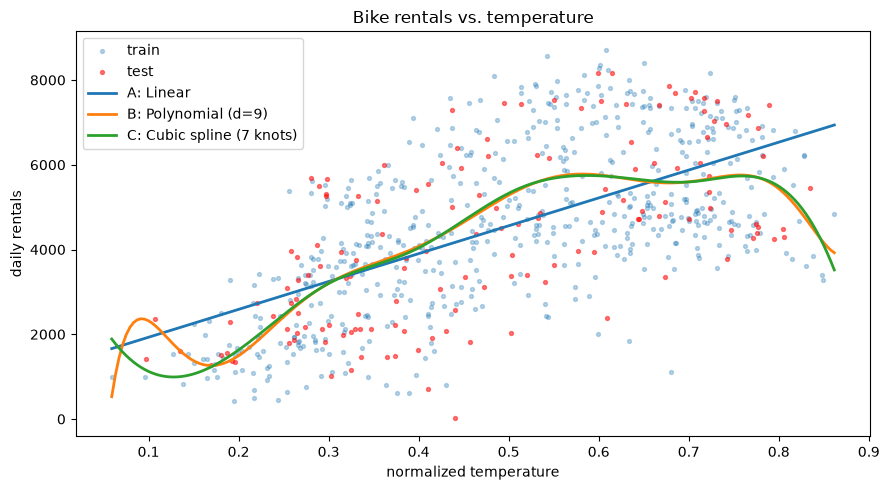

In [14]:
x1 = bike[["temp"]].values
yy = bike["cnt"].values
grid = np.linspace(x1.min(), x1.max(), 200)[:, None]

# One 80/20 split, reused in Part 4
x1_tr, x1_te, y1_tr, y1_te = train_test_split(x1, yy, test_size=0.2, random_state=42)

bike_models = {
    "A: Linear":                 make_pipeline(LinearRegression()),
    "B: Polynomial (d=9)":       make_pipeline(StandardScaler(), PolynomialFeatures(9, include_bias=False), LinearRegression()),
    "C: Cubic spline (7 knots)": make_pipeline(SplineTransformer(degree=3, n_knots=7, knots="quantile"), LinearRegression()),
}
for m in bike_models.values():
    m.fit(x1_tr, y1_tr)

plt.figure(figsize=(9, 5))
plt.scatter(x1_tr, y1_tr, s=8, alpha=0.3, label="train")
plt.scatter(x1_te, y1_te, s=8, alpha=0.5, color="red", label="test")
for name, m in bike_models.items():
    plt.plot(grid, m.predict(grid), lw=2, label=name)
plt.xlabel("normalized temperature"); plt.ylabel("daily rentals"); plt.legend()
plt.title("Bike rentals vs. temperature")
plt.tight_layout()
plt.show()

**d.** What do you observe?

***The linear model (A) is a straight line, so it misses the shape of the data. It predicts too low in the middle (around .5 to .7 normalized temp, where rentals are highest) and too high at the very hot and very cold ends. The polynomial (B) and spline (C) curves are almost on top of each other. They both rise until about .55, flatten out, and then drop off at the hot end (> .8), which makes sense since people probably don't rent bikes as much when it is really hot. The one place they differ is the far left (temp < .15), where there is very little data and the polynomial goes up and down (it even dips down to about 500 at the edge), while the spline is a bit smoother. Overall the data is very spread out, so none of the models are going to fit it tightly.***

### Question 2: Training and testing RMSE

In [15]:
rmse_table = pd.DataFrame({
    name: {"train RMSE": root_mean_squared_error(y1_tr, m.predict(x1_tr)),
           "test RMSE": root_mean_squared_error(y1_te, m.predict(x1_te))}
    for name, m in bike_models.items()}).T
display(rmse_table.round(1))
print("Smallest train RMSE:", rmse_table["train RMSE"].idxmin())
print("Smallest test RMSE: ", rmse_table["test RMSE"].idxmin())

,train RMSE,test RMSE
A: Linear,1497.7,1546.3
B: Polynomial (d=9),1379.3,1531.6
C: Cubic spline (7 knots),1380.6,1532.4


Smallest train RMSE: B: Polynomial (d=9)
Smallest test RMSE:  B: Polynomial (d=9)


**a.** Which model has the smallest training RMSE and which has the smallest test RMSE? (see output above)

***The polynomial (B) has both the smallest training RMSE (1379.3) and the smallest test RMSE (1531.6). The spline (C) is nearly identical (1380.6 train, 1532.4 test), and the linear model (A) is the highest on both (1497.7 and 1546.3). B and C are only about 1 rental apart, so I would call them tied.***

**b.** Does decreasing the training error imply decreasing the test error?

***Not necessarily. Going from A to B lowered the training RMSE by about 118 rentals (1497.7 to 1379.3), but the test RMSE only dropped by about 15 (1546.3 to 1531.6). So most of the improvement in the training error did not carry over to new data. The gap between train and test is about 49 for A, but about 152 for B and 152 for C, which shows the more flexible models are fitting the training set better than they should relative to the test set. Training error always goes down when we add flexibility, so it is not a good measure of how the model will do on new data.***

**c.** Is there evidence of overfitting or underfitting?

***The linear model shows some underfitting. It misses the curve in the data, as seen in the plot, and has the highest error for both train and test (1498 and 1546). However, its train/test gap is small (49), so it is stable and does not overfit. The polynomial and spline show a mild amount of overfitting. The train/test gap is about 3 times larger than for the linear model (about 152), and the polynomial has the wiggle on the far left where there is not much data. It isn't severe though, since the test RMSE for both is still lower than for the linear model, so the extra flexibility was worth it overall.***

### Question 3: 5-fold cross-validation

In [16]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
rmse_table["5-fold RMSE"] = [
    -cross_val_score(clone(m), x1, yy, cv=cv5, scoring="neg_root_mean_squared_error").mean()
    for m in bike_models.values()]
rmse_table.round(1)

,train RMSE,test RMSE,5-fold RMSE
A: Linear,1497.7,1546.3,1510.2
B: Polynomial (d=9),1379.3,1531.6,1433.9
C: Cubic spline (7 knots),1380.6,1532.4,1426.0


Does this give you more confidence in your answers around model complexity? Why or why not?

***Yes, I am more confident. With the single split, the test RMSE of the three models was very close (1546, 1532, 1532), so the difference between linear and the flexible models was only about 15 rentals, which could have been noise. With 5-fold, the difference is much clearer: linear is 1510, polynomial is 1434, and spline is 1426, so the flexible models are better by about 76 to 84 rentals. That tells us that the extra flexibility really does help, and that we were not just lucky or unlucky on the one split. The 5-fold RMSEs for B and C (about 1430) are also lower than the single split test RMSEs (about 1532), so that split was probably a harder test set than average. The cross-validation also flips the order of B and C (the spline is now a little better than the polynomial, 1426 vs 1434), which tells me they are really about equal and that the small gap between them in the earlier split was just noise.***

## Part 4: The Bias-Variance Tradeoff

### Question 1: Bootstrap predictions at temp = 0.60

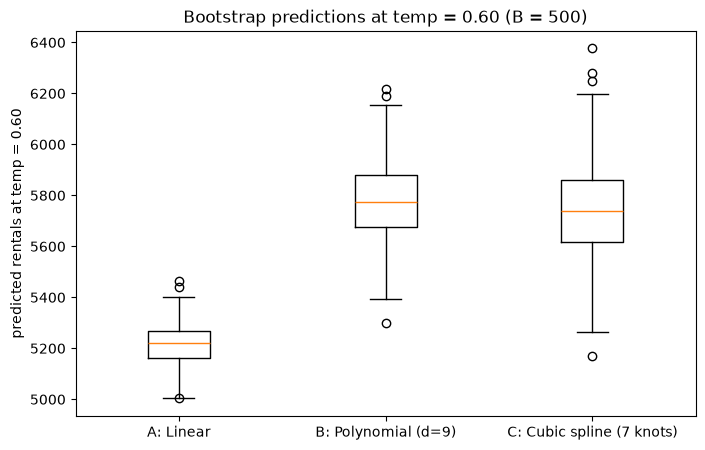

,mean,std,min,max
A: Linear,5217.1,74.5,5003.4,5466.1
B: Polynomial (d=9),5775.3,149.4,5299.1,6218.7
C: Cubic spline (7 knots),5743.7,179.6,5170.9,6376.4


In [17]:
B = 500
x0 = np.array([[0.60]])
rng = np.random.default_rng(42)
n_train = len(x1_tr)

boot = {name: [] for name in bike_models}
for b in range(B):
    idx = rng.integers(0, n_train, n_train)          # sample training rows with replacement
    for name, m in bike_models.items():
        fit = clone(m).fit(x1_tr[idx], y1_tr[idx])   # refit on the bootstrap sample
        boot[name].append(fit.predict(x0)[0])        # predict at x = 0.60
boot = pd.DataFrame(boot)

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([boot[c] for c in boot.columns], tick_labels=boot.columns)
ax.set(ylabel="predicted rentals at temp = 0.60", title=f"Bootstrap predictions at temp = 0.60 (B = {B})")
plt.show()

display(boot.agg(["mean", "std", "min", "max"]).T.round(1))

**a.** Compare the distributions of predictions. Which model is most stable? Which is most variable?

***The linear model (A) is the most stable. Its predictions at temp = 0.60 have a standard deviation of 74.5 and range from about 5003 to 5466. The spline (C) is the most variable (SD 179.6, range 5171 to 6376), with the polynomial (B) in between (SD 149.4, range 5299 to 6219). Also, the linear model's predictions are centered lower (mean 5217) than B and C (about 5775 and 5744), which matches the plot, where the line sits below the curves at 0.60.***

**b.** Compare prediction variability across the linear, polynomial, and spline models. What does this say about flexibility and sensitivity to the training sample?

***The variability goes up as the flexibility goes up. The SD goes from 74.5 (linear) to 149.4 (polynomial) to 179.6 (spline), so the flexible models are about 2 to 2.4 times as sensitive to which cars end up in the training sample. This makes sense because the linear model only has two parameters to estimate, so one or two unusual days will not move the line much, while the polynomial and spline have around 9 or 10 parameters and can bend towards whatever happens to be in the sample. The spline having a bit more variance than the polynomial at 0.60 is a bit surprising, but they are pretty close, and the spline is local so it relies on fewer data points in each part of the curve.***

**c.** Suppose a model fits the training observations very closely, but predictions at temp = 0.60 change substantially across bootstrap samples. What does that say about the model's variance and its ability to generalize?

***It tells us that the model has high variance. It is fitting the specific sample it was trained on, including the noise in it, instead of the pattern that would show up in any sample. If another sample of days could change the prediction that much, then we can't trust any one fitted model, so it will probably not generalize well to new data. The low training error is misleading in this case because it only shows how well the model memorized the training data, not how well it will do on new data. This is the definition of overfitting.***

### Question 2: Putting it all together

In [18]:
# Everything side by side: errors from Part 3, spread from Part 4
summary = rmse_table.copy()
summary["bootstrap SD at 0.60"] = boot.std().values
summary.round(1)

,train RMSE,test RMSE,5-fold RMSE,bootstrap SD at 0.60
A: Linear,1497.7,1546.3,1510.2,74.5
B: Polynomial (d=9),1379.3,1531.6,1433.9,149.4
C: Cubic spline (7 knots),1380.6,1532.4,1426.0,179.6


**a.** Describe the bias-variance tradeoff across the linear (A), polynomial (B), and spline (C) models.

***The linear model (A) has high bias and low variance. It misses the curve in the data (it underestimates the middle temperatures, with a mean prediction at 0.60 of about 550 lower than B and C), and has the highest train, test, and CV errors (1498, 1546, 1510). But it is the most stable (SD 74.5) and has the smallest gap between train and test error (about 49). The polynomial (B) and spline (C) have lower bias, because they follow the curve and the CV RMSE improves to 1434 and 1426. They also have more variance, with bootstrap SDs of 149 and 180, about double the linear one, and the train/test gap is about 152. B and C are nearly the same in all of the errors, with the spline having the lowest CV RMSE and the highest SD. In this data, the drop in bias was worth more than the increase in variance, because the test and CV errors are lower for B and C. The gain is not huge though (about 5% in CV), since there is so much noise in the data. I would pick the spline (or the polynomial, since they are so close) over the linear model, and I would lean towards the spline because it has the lowest CV RMSE and does not do as much wiggling on the far left of the plot.***

**b.** A teammate says: "We should just choose the model with the smallest training RMSE." Why is this reasoning incomplete?

***Training RMSE only measures how well the model fits data that it has already seen, and it almost always goes down when we add flexibility, even when the extra flexibility is just fitting noise. A model with the smallest training RMSE is just the most flexible one, so it has the most risk of overfitting (low bias, but high variance), and it might not do well on new data. We saw a bit of this in our results: going from linear to polynomial dropped the training RMSE by 118 but the test RMSE by only 15, and the bootstrap SD doubled. If we kept increasing the degree, the training error would keep going down while the model got more unstable. What we want is a model that generalizes, so we should use test error or cross-validation, which estimate how it does on unseen data, and balance that with bias and variance. In this case the polynomial happened to have the smallest training RMSE and a similar test RMSE to the spline, but we couldn't have known that from training error alone.***